# Регрессионный анализ

**Цель работы:**

Изучение алгоритмов регрессии на практике (простая, полиномиальная, сравнение методов и т.д.).

### Индивидуальный вариант

Вариант №1 (лист var1)

Набор данных: датасет regression.xlsx содержит информацию о признаках объектов $x1, x2, y$.  

### 1. Простая линейная регрессия

#### 1.1 Загрузка данных и их оценка 

Загрузка датасета с помощью библиотеки pandas. Исходные табличные данные преобразуются в датафрейм.

In [1]:
import pandas as pd

df = pd.read_excel('regression.xlsx', sheet_name='var1')
df.head()

,x1,x2,y
0,1.929428,1.511727,5.734255
1,-0.330281,-0.898878,-0.623706
2,0.688773,0.908247,1.028884
3,-0.008892,-0.518823,-0.894802
4,-1.698716,0.610347,2.822400


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      1000 non-null   float64
 1   x2      1000 non-null   float64
 2   y       1000 non-null   float64
dtypes: float64(3)
memory usage: 23.6 KB


Датасет содержит 1000 объектов, каждый из которых имеет 3 признака (без пропусков). Все столбцы содержат вещественные числа.  
Выведем числовые характеристики признаков:

In [3]:
df.describe()

,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,-0.000004,0.000028,1.328769
std,1.155279,1.155227,1.615985
min,-1.999458,-1.998031,-2.722868
25%,-0.999670,-0.999294,0.072635
50%,0.000488,-0.000001,1.256896
75%,0.998817,0.999619,2.418257
max,1.999308,1.997041,5.734255


Можно сказать, что масштабы трех переменных сопоставимы (все порядка единиц), сильной необходимости в стандартизации на этом этапе нет. Наибольший размах имеет признак y. Средние переменных x1 и x2 ≈ 0. 

#### 1.2 Подсчёт коэффициентов корреляции 

Корреляция – это статистическая мера **линейной** зависимости между двумя переменными. Наличие корреляции не доказывает причинно-следственную связь, а указывает на статистическую зависимость.
Корреляция может быть измерена с помощью коэффициента корреляции, такого как коэффициент Пирсона. Корреляция Пирсона измеряет степень и направление линейной взаимосвязи между двумя переменными. Коэффициент Пирсона (обозначается как r) показывает, насколько близко точки данных на диаграмме рассеяния ложатся на прямую линию.  
По его значению можно судить о силе линейной связи: 0.9 — сильная линейная связь, 0.1 — слабая. Чувствителен к выбросам.
Метод corr() по умолчанию считает именно коэффициент Пирсона:

In [4]:
df.corr(numeric_only=True)

,x1,x2,y
x1,1.000000,0.029707,0.031201
x2,0.029707,1.000000,0.577203
y,0.031201,0.577203,1.000000


По корреляционной матрице можно сделать промежуточный вывод об отсутствии сильной линейной связи между признаками объектов $x1$ и $x2$, а также $x1$ и $y$. Значение $r(x2, y)≈0,6$ может говорить о наличии умеренной положительной связи. Для визуального анализа построим матрицу диаграмм рассеяния для нескольких признаков набора данных, которая отражает попарные взаимосвязи величин: 

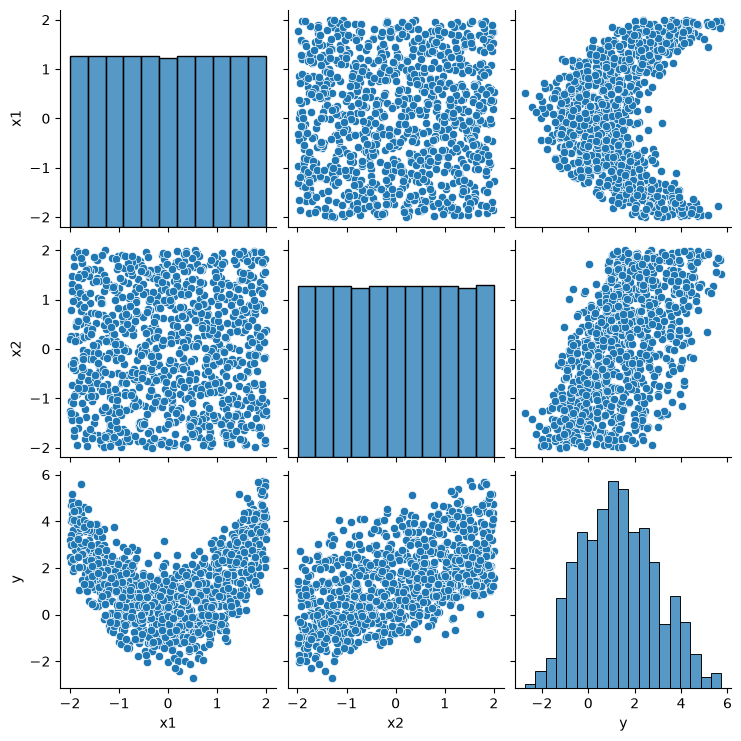

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(df[['x1', 'x2', 'y']])

По полученным диаграммам рассеивания можно сделать вывод:
- Зависимость $x1-y$ явно описывается нелинейной функцией (скопление точек напоминает параболическую функцию). В дальнейшем для $x1$ стоит использовать полиномиальную регрессию;
- Точки на диаграмме $x1-x2$ визуально равномерно распределены по всей декартовой плоскости, что говорит об однозначном отсутствии зависимости между переменными;
- Точки $x2-y$ образуют широкую полосу, чётко прослеживается возрастающее направление: бОльшим значениям фичи $x2$ соответствуют бОльшие значения y (что подтверждает полученный выше положительный r). Для $x2$ линейная модель может быть подходящей.

По диагонали стоят гистограммы, которые показывают распределение каждого признака по отдельности:
- Признаки $x_1$ и $x_2$ выглядят примерно равномерно распределёнными на отрезке примерно $[-2, 2]$ (плоские гистограммы, почти одинаковая плотность);
- $y$ имеет сложное распределение с двумя пиками (бимодальное)

Обучить модель простой (парной) линейной регрессии, используя для обучения значения и , а затем и
y.
х1 y х2
Не забудьте разделить выборку. 
    

#### 1.3 Обучение модели парной линейной регрессии

Цель задачи регрессии - построить модель, которая может предсказать численные значения для
новых наблюдений, основываясь на известных данных.
Для этого модель анализирует связь между независимыми переменными (предикторами) и
зависимой переменной (целевой переменной).  
Наиболее распространенной формой регрессии является линейная регрессия, где предполагается, что
зависимая переменная линейно зависит от независимых переменных.
При этом если независимая переменная одна – это простая линейная регрессия, а если две и более, то – это
множественная линейная регрессия.


Целевой признак находится в столбце `y`. В данном примере предиктором является признак, находящийся в столбце `x1`.  
Функция `train_test_split` принимает эти столбцы в качестве параметров и делит данные на 4 выборки: `X_train, X_test, y_train, y_test`. Можно задать размер
валидационной выборки параметром `test_size`, который выражается в долях – от 0 до 1. Некоторые объекты `scikit-learn` по своей природе случайны, и их случайность
контролируется с помощью `random_state` параметра. Он позволяет получать повторяемые результаты при каждом запуске модели.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import numpy as np


X_train1, X_test1, y_train1, y_test1 = train_test_split(
 df['x1'],
 df['y'],
 test_size=0.25,
 random_state=15)

model_x1 = LinearRegression()
model_x1.fit(np.array(X_train1).reshape(-1, 1), y_train1)
predictions_valid1 = model_x1.predict(np.array(X_test1).reshape(-1, 1))
df_match1 = pd.DataFrame({'Actual': y_test1, 'Predicted (x1)':
predictions_valid1})
display(df_match1)

,Actual,Predicted (x1)
825,-0.229188,1.266898
374,-0.181388,1.231412
488,1.152927,1.195584
608,0.953596,1.224287
42,4.793899,1.413391
...,...,...
827,0.385307,1.355918
690,1.091206,1.274239
907,-1.424944,1.299259
299,-2.004640,1.317749


При визуальном анализе фрагмента полученной таблицы наблюдается существенное расхождение между предсказанными и реальными значениями целевого признака (встречаются пары `(-2.004640; 1.317749)`, тогда как `std(y) ≈ 1.62`. Данный результат вызван нелинейностью связи признаков `x1` и `y`, которая прослеживается на диаграмме рассеивания и согласуется с `r ≈ 0.03`. Построим аналогичную таблицу для связи признаков `x2` и `y`:

In [7]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
 df['x2'],
 df['y'],
 test_size=0.25,
 random_state=15)

model_x2 = LinearRegression()
model_x2.fit(np.array(X_train2).reshape(-1, 1), y_train2)
predictions_valid2 = model_x2.predict(np.array(X_test2).reshape(-1, 1))
df_match2 = pd.DataFrame({'Actual': y_test2, 'Predicted (x2)':
predictions_valid2})
display(df_match2)

,Actual,Predicted (x2)
825,-0.229188,0.029760
374,-0.181388,0.325638
488,1.152927,-0.050535
608,0.953596,0.311600
42,4.793899,2.742728
...,...,...
827,0.385307,1.168630
690,1.091206,2.533288
907,-1.424944,0.466791
299,-2.004640,0.304009


Модель по `x_2`показывает меньшие отклонения, что соответствует умеренной положительной корреляции.

#### 1.4 Метрики качества линейной регрессии.
Оценку качества работы моделей проводят с использованием метрик качества регрессии ( MSE , MAE , RMSE , R2 ).


In [8]:
from sklearn import metrics

print('____________________x1___________________')
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test1, predictions_valid1))
print('Mean Squared Error:', metrics.mean_squared_error(y_test1, predictions_valid1))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test1, predictions_valid1)))
print('R2 metric:', metrics.r2_score(y_test1, predictions_valid1))

print('____________________x2___________________')
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test2, predictions_valid2))
print('Mean Squared Error:', metrics.mean_squared_error(y_test2, predictions_valid2))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test2, predictions_valid2)))
print('R2 metric:', metrics.r2_score(y_test2, predictions_valid2))

____________________x1___________________
Mean Absolute Error: 1.3659800153322441
Mean Squared Error: 2.805167704050783
Root Mean Squared Error: 1.6748634881836737
R2 metric: -0.006663004440029097
____________________x2___________________
Mean Absolute Error: 1.1064481175550946
Mean Squared Error: 1.7814133155766667
Root Mean Squared Error: 1.3346959637223252
R2 metric: 0.3607216859732474


Интерпретация:
- MAE равна средней абсолютной ошибке, оценить её можно только зная масштаб целевого признака;
- MSE - среднеквадратическая ошибка. В отличие от MAE более подвержена выбросам. RMSE возвращает размерность ошибки к шкале целевого признака.
- Коэффициент детерминации R2 – метрика, которую нужно максимизировать, определяет долю изменений,
обусловленных влиянием признаков на целевую переменную.

По значениями MAE, MSE, RMSE нельзя однозначно говорить об ошибке, важно сопоставлять полученные метрики с масштабом целевой переменной. Известно, что среднее `y ≈  1.3`, а стандартное кв. отклонение `std ≈ 1.6`.  
Модель по `x_1`: $R^2 < 0$, MAE и RMSE сравнимы со стандартным отклонением `y`. Линейная регрессия не улавливает зависимость и работает хуже предсказания средним.  
Модель по `x_2`: $R^2$ положительный, но невысокий (`≈ 0.3`); ошибки меньше, чем у модели по `x_1`, однако всё ещё значительны относительно масштаба `y`. Линейная связь есть, но объясняет лишь умеренную долю дисперсии. 

#### 1.5 Визуализация регрессии
Чтобы построить линию регрессии необходимо получить коэффициенты с помощью `coef_` и `intercept_`
(свободный коэффициент), по которым строится график. Это коэффициенты в формуле `y = ax + b` – график прямой линии.
Таким образом, можно построить распределение точек исходного датасета df и линию регрессии по формуле.  
Построим диаграммы рассеивания исходных наблюдений с наложенными теоретическими линиями регрессии:

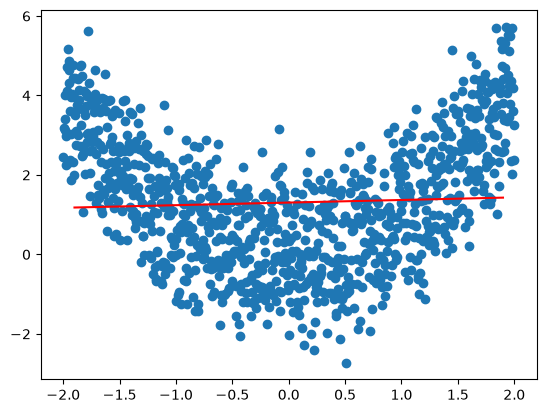

In [9]:
# Получение коэф регрессии
a1 = model_x1.coef_
b1 = model_x1.intercept_

plt.scatter(df['x1'], df['y']) # зависимость целевого столбца от конкретного столбца х1 (точечный график)
plt.plot([-1.9, 1.9], [a1*(-1.9) + b1, a1*(1.9) + b1], "r")
# df.columns

Линия регрессии не учитывает U-образную форму облака точек, никак не сопоставляется с его непостоянным характером. Отсюда и низкие метрики точности предсказаний `model_x1`, линейная модель непригодна для этой пары признаков.

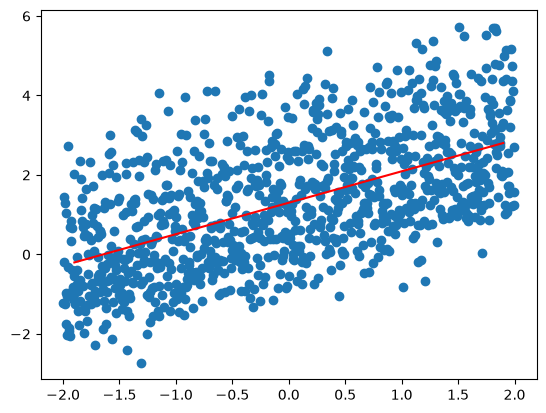

In [10]:
a2 = model_x2.coef_
b2 = model_x2.intercept_

plt.scatter(df['x2'], df['y']) # зависимость целевого столбца от конкретного столбца х1 (точечный график)
plt.plot([-1.9, 1.9], [a2*(-1.9) + b2, a2*(1.9) + b2], "r")
# df.columns

Здесь же линия регрессии достаточно хорошо описывает траекторию диаграммы рассеивания, но из-за значительного разброса точек вокруг неё метрики качества предсказательной способности модели `model_x2` показывают умеренные значения.

#### 1.6 Диагностический анализ остатков регрессии
##### 1.6.1 График остатков
Остатки в контексте регрессионных моделей представляют собой разницу между наблюдаемым значением целевой переменной и прогнозируемым значением - ошибка прогноза $e = y - \hat{y}$. График, представляющий разницу предсказанного и истинного значения в каждой точке, называется **графиком остатков (Residuals Plot)**. Он показывает разницу между остатками на вертикальной оси и зависимой переменной на горизонтальной оси (отложены предсказанные значения $\hat{y}$, а не истинные $y$), что позволяет обнаружить области внутри цели, которые могут быть подвержены
большей или меньшей ошибке.  
Если точки хаотично и симметрично рассеяны полосой постоянной ширины вдоль горизонтальной оси `e = 0`, можно говорить о состоятельности гипотез классической
линейной регрессии. 

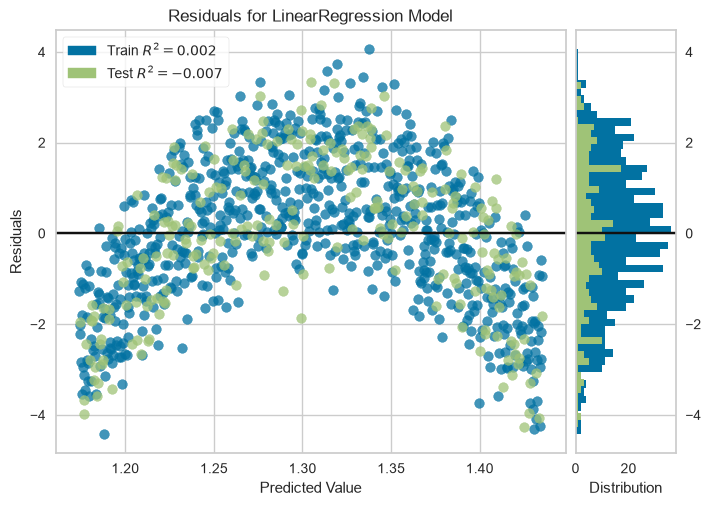

<Axes: title={'center': 'Residuals for LinearRegression Model'}, xlabel='Predicted Value', ylabel='Residuals'>

In [11]:
from yellowbrick.regressor import ResidualsPlot

visualizer1 = ResidualsPlot(LinearRegression(), force_model=True)
visualizer1.fit(np.array(X_train1).reshape(-1, 1), y_train1)
visualizer1.score(np.array(X_test1).reshape(-1, 1), y_test1)
visualizer1.show()

Облако остатков имеет выраженную криволинейную форму. Наибольшие отклонения наблюдаются по краям и в центре промежутка значений `y`. Такая форма облака остатков сигнализирует о том, что линейная модель **упускает нелинейную зависимость**. Значения $R^2$ для обеих выборок примерно одинаковы и ≈ 0, значит, модель почти ничего не объясняет.  
Гистограммы остатков для train и test схожи, что говорит о корректности разбиения.

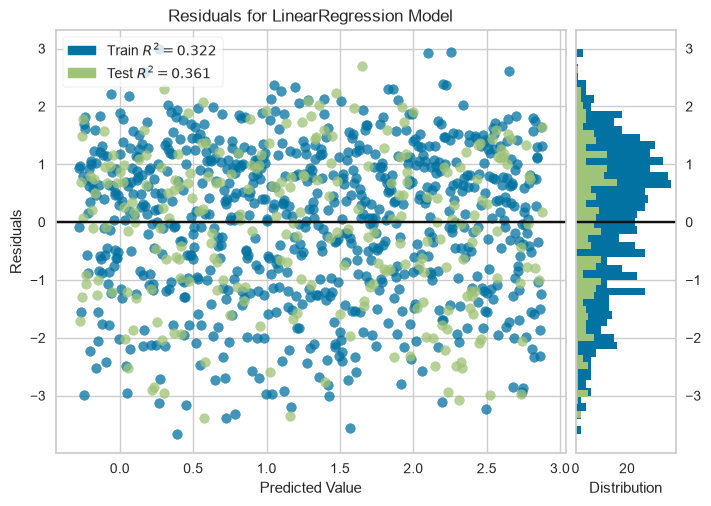

<Axes: title={'center': 'Residuals for LinearRegression Model'}, xlabel='Predicted Value', ylabel='Residuals'>

In [12]:
visualizer2 = ResidualsPlot(LinearRegression(), force_model=True)
visualizer2.fit(np.array(X_train2).reshape(-1, 1), y_train2)
visualizer2.score(np.array(X_test2).reshape(-1, 1), y_test2)
visualizer2.show()

В целом остатки рассеяны без явной кривизны, хотя наблюдается некоторая **асимметрия плотности**. Это согласуется с наличием умеренной линейной связи. Разница $R^2$ между train и test невелика. Сходство гистограмм остатков также указывает на удачное разбиение данных.  
##### 1.6.2 График ошибок прогнозирования
График ошибок прогнозирования показывает фактические цели из набора данных в сравнении с
прогнозируемыми значениями, сгенерированными моделью. Это позволяет нам увидеть, насколько велика
дисперсия в модели.  
По графикам можно оценить разницу между истинными и предсказанными: чем ближе точка к красной прямой, чем точнее сделан прогноз для данного значения целевого признака. 

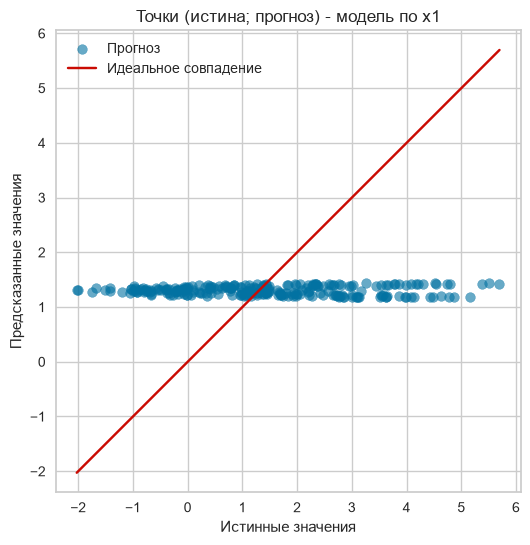

In [13]:
# from yellowbrick.regressor import PredictionError
plt.figure(figsize=(6, 6))
plt.scatter(y_test1, predictions_valid1, alpha=0.6, label='Прогноз')
# линия идеального совпадения под 45 градусов
min_val = min(y_test1.min(), predictions_valid1.min())
max_val = max(y_test1.max(), predictions_valid1.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r', label='Идеальное совпадение')
plt.xlabel('Истинные значения')
plt.ylabel('Предсказанные значения')
plt.legend()
plt.title('Точки (истина; прогноз) - модель по x1')
plt.axis('equal') 
plt.show()

In [14]:
#pd.Series(predictions_valid1).describe()

Все предсказания сконцентрированы около $\hat{y}$ ≈ 1.3. Модель практически не использует информацию о признаке $x_1$ и предсказывает значение, близкое к среднему целевой переменной.   
Существенное отклонение точек от линии идеального совпадения подтверждает **низкую предсказательную способность** линейной модели для данной пары признаков и согласуется с ранее полученными метриками ($R^2 \approx 0$) и графиком остатков.

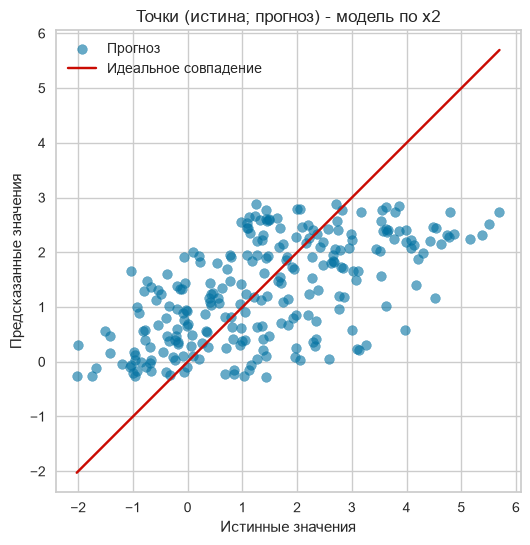

In [15]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test2, predictions_valid2, alpha=0.6, label='Прогноз')
# линия идеального совпадения
min_val = min(y_test2.min(), predictions_valid2.min())
max_val = max(y_test2.max(), predictions_valid2.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r', label='Идеальное совпадение')
plt.xlabel('Истинные значения')
plt.ylabel('Предсказанные значения')
plt.legend()
plt.title('Точки (истина; прогноз) - модель по x2')
plt.axis('equal')
plt.show()

Точки в целом располагаются вокруг линии идеального совпадения, что свидетельствует о наличии линейной связи. Разброс относительно стабильный по всей длине, явной кривизны нет. Наблюдается небольшая асимметрия (облако чуть плотнее слева, где $\hat{y} > y$), что может указывать на систематическое смещение, но оно не очень сильное.

### 2. Полиномиальная регрессия

**Полиномиальная регрессия** – это алгоритм машинного обучения, который используется для обучения линейной модели **на нелинейных данных** и позволяет более точно оценить данные, так как иногда данные намного сложнее, чем прямая линия.  
В данном случае целесообразнее применять полиномиальную регрессию для обучения модели по х1, поскольку именно в ней были особенно низкие метрики предсказания в предыдущем разделе. Уже в начале анализа U-образная форма точек на диаграмме рассеивания `(x1-y)` (см. пункт 1.5) указывала, что линейная модель непригодна для этой пары признаков.

In [16]:
from sklearn.preprocessing import PolynomialFeatures

`Polynomial Features` преобразователь, который преобразует матрицу входных данных в новую
матрицу данных заданной степени.  
#### 2.1 Полином второй степени

In [17]:
poly_dg2 = PolynomialFeatures(degree=2) # создание преобразователя
X_train_poly_dg2 = poly_dg2.fit_transform(np.array(X_train1).reshape(-1, 1)) # преобразованиe train выборки

# обучение лин регрессии на преобразованных данных
lin_reg_dg2 = LinearRegression()
lin_reg_dg2.fit(X_train_poly_dg2, y_train1)

X_test_poly_dg2 = poly_dg2.transform(np.array(X_test1).reshape(-1, 1)) # преобразованиу test выборки

predictions_poly_dg2 = lin_reg_dg2.predict(X_test_poly_dg2)

`predictions_poly_dg2` - предсказания полиномиальной модели степени 2 на тестовой выборке.

In [18]:
print(lin_reg_dg2.intercept_)    # w0
print(lin_reg_dg2.coef_)         # w1, w2  (при x и x^2)

0.024006632467536093
[0.         0.07811176 0.97716356]


Полученная модель: $\hat{y} = 0.024 + 0.078\,x + 0.977\,x^2$  
Сравнение коэфициентов при признаках указывает на особую важность признака $x^2$, что ожидаемо для U-образной зависимости.

In [19]:
predictions_train_poly_dg2 = lin_reg_dg2.predict(X_train_poly_dg2)
print('____________________x1 (полиномиальная)___________________')
print('MAE train:', metrics.mean_absolute_error(y_train1, predictions_train_poly_dg2))
print('MAE test:',  metrics.mean_absolute_error(y_test1, predictions_poly_dg2))
print('R2 train:',  metrics.r2_score(y_train1, predictions_train_poly_dg2))
print('R2 test:',   metrics.r2_score(y_test1, predictions_poly_dg2))

____________________x1 (полиномиальная)___________________
MAE train: 0.9075629342425287
MAE test: 0.928274466433198
R2 train: 0.5308635132479647
R2 test: 0.567567636732403


Полученные значения метрик перенесем в таблицу:
| Степень полинома | $R^2$ train | $R^2$ test | MAE train | MAE test |
|------------------|---------------|--------------|-----------|----------|
| 2                | 0.531         | 0.568        | 0.908     | 0.928    |

В сравнении с моделью линейной регрессии без преобразования признаков-предикторов (MAE ≈  1.37, $R^2$ ≈ -0.01) предсказательная способность заметно выросла. 

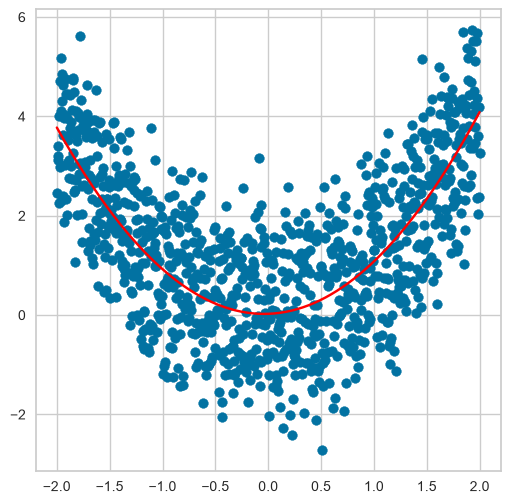

In [20]:
plt.figure(figsize=(6, 6))
x_line = np.linspace(df['x1'].min(), df['x1'].max(), 300).reshape(-1, 1)
y_line = lin_reg_dg2.predict(poly_dg2.transform(x_line))
plt.scatter(df['x1'], df['y'])
plt.plot(x_line, y_line, color='red')

Построенная парабола хорошо описывает U-образную форму облака точек, что подтверждает целесообразность полиномиальной регрессии степени 2 для признака $x_1$. Наблюдается заметный разброс значений $y$ вокруг кривой (особенно вблизи вершины), однако систематическая кривизна, которая была видна при линейной модели, теперь отсутствует. Это согласуется с существенным улучшением метрик по сравнению с простой линейной регрессией.

#### 2.2 Полином третьей степени


In [21]:
poly_dg3 = PolynomialFeatures(degree=3) # создание преобразователя
X_train_poly_dg3 = poly_dg3.fit_transform(np.array(X_train1).reshape(-1, 1)) # преобразованиe train выборки

# обучение лин регрессии на преобразованных данных
lin_reg_dg3 = LinearRegression()
lin_reg_dg3.fit(X_train_poly_dg3, y_train1)

X_test_poly_dg3 = poly_dg3.transform(np.array(X_test1).reshape(-1, 1)) # преобразованиу test выборки

predictions_poly_dg3 = lin_reg_dg3.predict(X_test_poly_dg3)

`predictions_poly_dg3` - предсказания полиномиальной модели степени 3 на тестовой выборке.

In [22]:
print(lin_reg_dg3.intercept_)    # w0
print(lin_reg_dg3.coef_)         # w1, w2, w3  (при x, x^2, x^3)

0.023965122659502125
[ 0.          0.08186106  0.97717519 -0.00157078]


Полученная модель: $\hat{y} = 0.024 + 0.081\,x + 0.977\,x^2 - 0.002\,x^3$  
Сравнение коэфициентов при признаках в очередной раз указывает на особую важность признака $x^2$, при этом коэффициент при $x^3$ принимает близкое к нулю значение, что говорит об очень маленьком вкладе переменной в прогнозирование целевого признака. 

In [23]:
predictions_train_poly_dg3 = lin_reg_dg3.predict(X_train_poly_dg3)
print('____________________x1 (полиномиальная)___________________')
print('MAE train:', metrics.mean_absolute_error(y_train1, predictions_train_poly_dg3))
print('MAE test:',  metrics.mean_absolute_error(y_test1, predictions_poly_dg3))
print('R2 train:',  metrics.r2_score(y_train1, predictions_train_poly_dg3))
print('R2 test:',   metrics.r2_score(y_test1, predictions_poly_dg3))

____________________x1 (полиномиальная)___________________
MAE train: 0.9075415489700284
MAE test: 0.9284025789620158
R2 train: 0.530864949432183
R2 test: 0.5674772852589349


Таблица метрик примет вид:
| Степень полинома | $R^2$ train | $R^2$ test | MAE train | MAE test |
|------------------|---------------|--------------|-----------|----------|
| 2                | 0.531         | 0.568        | 0.908     | 0.928    |
| 3                | 0.531         | 0.567        | 0.908     | 0.928    |

Метрики изменились незначительно (разница исчисляется в десятитысячных). 

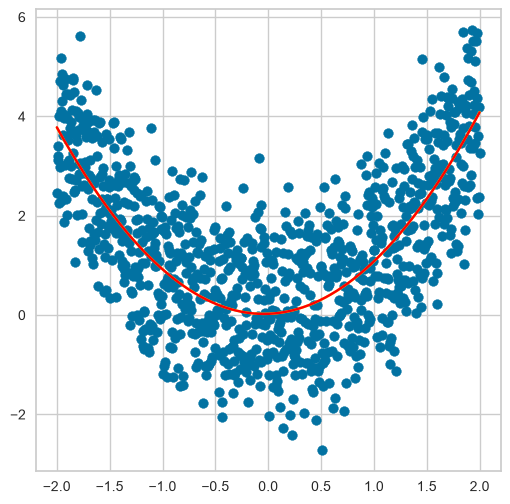

In [24]:
plt.figure(figsize=(6, 6))
x_line = np.linspace(df['x1'].min(), df['x1'].max(), 300).reshape(-1, 1)
y_line1 = lin_reg_dg2.predict(poly_dg2.transform(x_line))
y_line2 = lin_reg_dg3.predict(poly_dg3.transform(x_line))

plt.scatter(df['x1'], df['y'])
plt.plot(x_line, y_line1, color='yellow')
plt.plot(x_line, y_line2, color='red')

Линии практически накладываются друг на друга, разница незначительна.  
#### 2.3 Полином четвертой степени

In [25]:
poly_dg4 = PolynomialFeatures(degree=4) # создание преобразователя
X_train_poly_dg4 = poly_dg4.fit_transform(np.array(X_train1).reshape(-1, 1)) # преобразованиe train выборки

# обучение лин регрессии на преобразованных данных
lin_reg_dg4 = LinearRegression()
lin_reg_dg4.fit(X_train_poly_dg4, y_train1)

X_test_poly_dg4 = poly_dg4.transform(np.array(X_test1).reshape(-1, 1)) # преобразованиу test выборки

predictions_poly_dg4 = lin_reg_dg4.predict(X_test_poly_dg4)
print(lin_reg_dg4.intercept_)    # w0
print(lin_reg_dg4.coef_)         # w1, w2, w3  (при x, x^2, x^3)

0.028727114926340613
[ 0.          0.08212152  0.96528626 -0.00168701  0.00345807]


In [26]:
predictions_train_poly_dg4 = lin_reg_dg4.predict(X_train_poly_dg4)
print('____________________x1 (полиномиальная)___________________')
print('MAE train:', metrics.mean_absolute_error(y_train1, predictions_train_poly_dg4))
print('MAE test:',  metrics.mean_absolute_error(y_test1, predictions_poly_dg4))
print('R2 train:',  metrics.r2_score(y_train1, predictions_train_poly_dg4))
print('R2 test:',   metrics.r2_score(y_test1, predictions_poly_dg4))

____________________x1 (полиномиальная)___________________
MAE train: 0.9075453322512395
MAE test: 0.9283642414053461
R2 train: 0.5308719990288442
R2 test: 0.5677054737673856


Коэффициент при $x^4$ принимает близкое к нулю значение, что говорит об очень маленьком вкладе переменной в прогнозирование целевого признака.  
Таблица метрик примет вид:
| Степень полинома | $R^2$ train | $R^2$ test | MAE train | MAE test |
|------------------|---------------|--------------|-----------|----------|
| 2                | 0.531         | 0.568        | 0.908     | 0.928    |
| 3                | 0.531         | 0.567        | 0.908     | 0.928    |
| 4                | 0.531         | 0.568        | 0.908     | 0.928    |

#### 2.4 Вывод по полиномиальной регрессии  
Оптимальной является степень полинома 2.  
При увеличении степени до 3 и 4 метрики $R^2$ и MAE на обучающей и тестовой выборках практически не изменяются, а коэффициенты при $x^3$ и $x^4$ близки к нулю. Дополнительные признаки не несут новой информации о зависимости. Слишком низкая степень приводит к недообучению (случай простой линейной регрессии): модель не улавливает U-образную форму и даёт $R^2 \approx 0$.
Слишком высокая степень в общем случае повышает риск переобучения ($R^2$ на train растёт, а на test падает). В данном наборе данных этот эффект не наблюдается, т.к. истинная форма зависимости относительно проста и датасет содержит достаточный объём данных. Степень 2 остаётся предпочтительной для простоты и интерпретируемости модели.  

### 3. Решение задачи регрессии различными методами

#### 3.1 Чтение файла и обзор данных
Набор данных: датасет `salary.csv` содержит информацию о доходах и статусе сотрудников.
Атрибуты:
1. `age` - возраст сотрудника в годах.
2. `income` - годовой доход до текущей работы.
3. `experience` - количество полных лет профессионального опыта.
4. `score_test` - результат прохождения профессионального теста
5. `hours_worked` - среднее количество рабочих часов в неделю.
6. `distance_to_work` - расстояние от дома до места работы.
7. `savings` - сумма сбережений на банковском счёте.
8. `debt` - общий объём текущих долгов (по кредитам, картам и другим обязательствам, в долларах).
9. `education` - уровень образования: «High School» (школа), «Bachelor» (бакалавр), «Master» (магистр) или
«PhD» (доктор наук).
10. `city` - город проживания: Нью-Йорк, Лос-Анджелес, Чикаго, Хьюстон или Финикс.
11. `job_type` - сфера профессиональной деятельности: IT, финансы, здравоохранение, образование или
ритейл.
12. `marital_status` - семейное положение: «Single» (холост/незамужем), «Married» (в браке) или «Divorced»
(в разводе).
13. `car` - наличие автомобиля: «Yes» (есть) или «No» (нет).
14. `remote_work` - работает ли сотрудник удалённо: «Yes» или «No».
15. `salary` - годовая зарплата

In [27]:
df_salary = pd.read_csv('salary.csv')
df_salary.head()

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,PhD,Chicago,Finance,Single,Yes,Yes,106233.833479
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,High School,Houston,Retail,Single,No,Yes,87205.291042
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,PhD,Los Angeles,Finance,Married,Yes,No,69369.283522
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,Bachelor,Los Angeles,IT,Married,Yes,No,76587.116955
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,Bachelor,Phoenix,IT,Married,No,No,71023.148842


In [28]:
df_salary.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1500 non-null   int64  
 1   income            1500 non-null   float64
 2   experience        1500 non-null   int64  
 3   score_test        1500 non-null   float64
 4   hours_worked      1500 non-null   int64  
 5   distance_to_work  1500 non-null   float64
 6   savings           1500 non-null   float64
 7   debt              1500 non-null   float64
 8   education         1500 non-null   str    
 9   city              1500 non-null   str    
 10  job_type          1500 non-null   str    
 11  marital_status    1500 non-null   str    
 12  car               1500 non-null   str    
 13  remote_work       1500 non-null   str    
 14  salary            1500 non-null   float64
dtypes: float64(6), int64(3), str(6)
memory usage: 224.5 KB


Пропусков нет, типы данных корректны. 

In [29]:
df_salary.describe()

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,salary
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,43.732000,50493.562171,19.479333,74.649867,49.046000,10.169171,19920.723043,7656.749308,98573.093521
std,15.071771,15354.495706,11.471529,9.904426,17.053654,10.003094,13635.530107,5481.390395,111786.756001
min,18.000000,-826.421240,0.000000,41.604998,20.000000,0.018137,408.482014,4.367130,28588.984258
25%,31.000000,40525.989722,10.000000,67.776127,34.000000,3.022163,9418.707911,3138.484219,69582.654903
50%,44.000000,50784.690569,19.000000,74.701567,49.000000,7.105165,17114.512522,6786.703775,80310.412797
75%,56.000000,61104.997961,29.000000,81.635633,63.000000,14.392065,27766.214001,11008.309571,91637.052601
max,69.000000,98819.709397,39.000000,107.261317,79.000000,82.597342,101890.570518,27276.705593,985625.114794


Аномальных значений в данных не обнаружено (считаем, что годовой доход до текущей работы может быть отрицательным).

In [30]:
print(df_salary.duplicated().sum())
print('______________________________')
print(df_salary['education'].value_counts())
print('______________________________')
print(df_salary['city'].value_counts())
print('______________________________')
print(df_salary['job_type'].value_counts())
print('______________________________')
print(df_salary['marital_status'].value_counts())
print('______________________________')
print(df_salary['car'].value_counts())
print('______________________________')
print(df_salary['remote_work'].value_counts())

0
______________________________
education
Bachelor       900
PhD            200
High School    200
Master         200
Name: count, dtype: int64
______________________________
city
New York       600
Los Angeles    300
Chicago        250
Houston        200
Phoenix        150
Name: count, dtype: int64
______________________________
job_type
Retail        500
IT            500
Finance       200
Healthcare    200
Education     100
Name: count, dtype: int64
______________________________
marital_status
Married     717
Single      639
Divorced    144
Name: count, dtype: int64
______________________________
car
Yes    1050
No      450
Name: count, dtype: int64
______________________________
remote_work
Yes    883
No     617
Name: count, dtype: int64


Ни явных, ни неявных дубликатов не обнаружено.  

#### 3.2 Целевой признак
В качестве целевой выбран признак `salary` - годовая зарплата, на который наверняка оказывают влияние остальные атрибуты.  

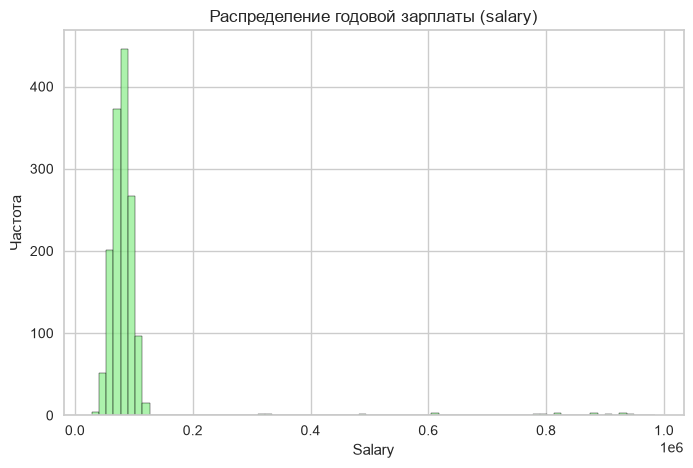

In [31]:
plt.figure(figsize=(8, 5))
sns.histplot(df_salary['salary'], color='lightgreen', edgecolor='black')
plt.title('Распределение годовой зарплаты (salary)')
plt.xlabel('Salary')
plt.ylabel('Частота')
plt.show()

Text(0.5, 1.0, 'Boxplot для salary (годовая зарплата)')

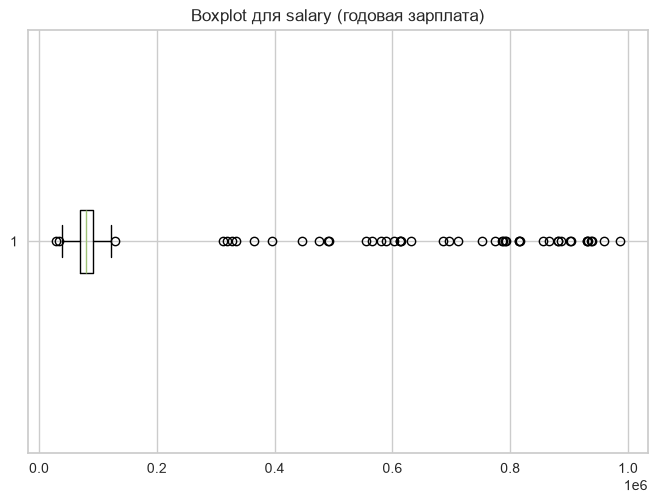

In [32]:
plt.boxplot(df_salary['salary'], orientation = 'horizontal')
plt.title('Boxplot для salary (годовая зарплата)')

На обоих графиках явно выражена сильная **правосторонняя асимметрия**: основная масса значений сосредоточена в нижней части диапазона (ящик и усы слева), а медиана заметно меньше среднего. Наблюдается значительное количество выбросов в сторону высоких зарплат (вплоть до порядка $10^6$). Эти выбросы могут соответствовать высоким доходам и не являться ошибками данных, однако они искажают данные о "типичной" зарплате", поэтому для дальнейшего анализа будут удалены.

In [33]:
Q1 = df_salary['salary'].quantile(0.25)
Q3 = df_salary['salary'].quantile(0.75)
IQR = Q3 - Q1

# концы усов боксплота
lower = Q1 - 1.5 * IQR 
upper = Q3 + 1.5 * IQR
df_salary_clean = df_salary[(df_salary['salary'] >= lower) & 
                            (df_salary['salary'] <= upper)]

print(f'Было: {len(df_salary)}, стало: {len(df_salary_clean)}')
print(f'Границы: {lower:.0f} – {upper:.0f}')

Было: 1500, стало: 1452
Границы: 36501 – 124719


Было удалено 48 строк, что составляет 3,2% исходных данных.

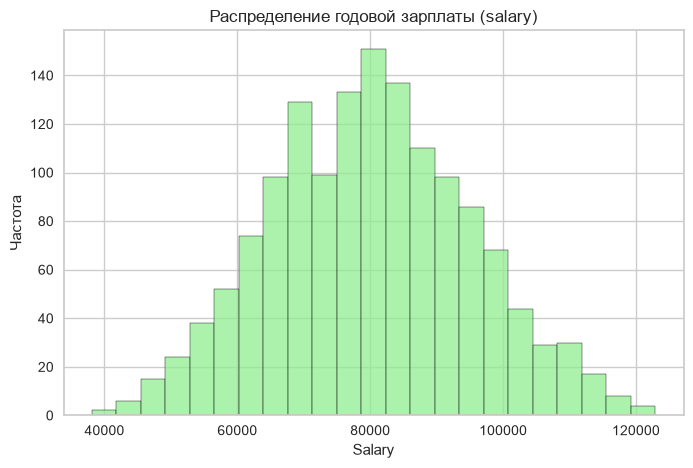

In [34]:
plt.figure(figsize=(8, 5))
sns.histplot(df_salary_clean['salary'], color='lightgreen', edgecolor='black')
plt.title('Распределение годовой зарплаты (salary)')
plt.xlabel('Salary')
plt.ylabel('Частота')
plt.show()

Теперь, когда гистограмма хорошо просматривается, видно, что зарплата имеет распределние, похожее на нормальное, но ближе к середине имеет два пика. 

Text(0.5, 1.0, 'Boxplot для salary (годовая зарплата)')

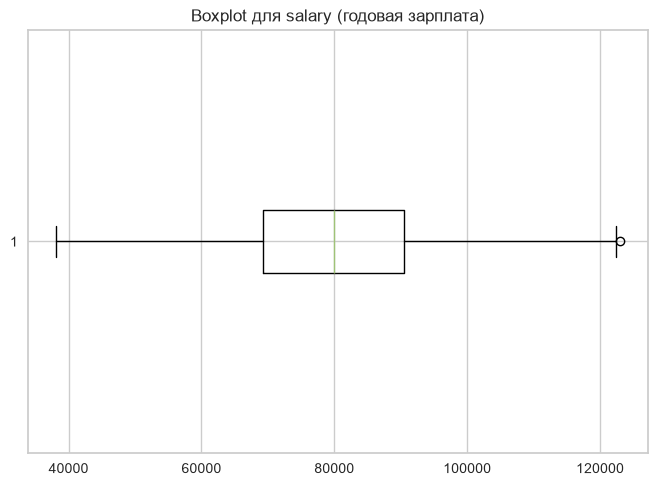

In [35]:
plt.boxplot(df_salary_clean['salary'], orientation = 'horizontal')
plt.title('Boxplot для salary (годовая зарплата)')

 На боксплоте очищенных данных выбросы практически отсутствуют, ящик расположился более симметрично. После удаления экстремально высоких значений распределение salary стало значительно ближе к симметричному, и среднее значение приблизилось к медиане.

#### 3.3 Кодирование признаков
В связи с тем, что многие алгоритмы машинного обучения не работают с качественными переменными,
используется категориальное кодирование для преобразования качественных столбцов в численные.  

**Прямое кодирование (One-Hot Encoding)**:
Категориальный признак, содержащий C уникальных градаций, преобразуется в C независимых
бинарных признаков (дамми-переменных), принимающих значение 1 при наличии категории у
объекта и 0 - в противном случае. Новые признаки – это **дамми-признаки** (фиктивные). При этом чтобы избежать вырождения матрицы признаков, удаляют один базовый столбец (параметр drop='first'). Для прямого кодирования в библиотеке pandas есть функция `pd.get_dummies()`. Может применяться для
конкретного столбца или всего набора данных.В данном датасете прямому кодированию подвергаются `city`, `job_type`, `marital_status`.


**Порядковое кодирование (Ordinal Encoding)**:
Каждому новому значению признака присваивается новая метка, обычно это числа от 0 до `N–1`,
где N – количество уникальных значений признака. Порядковое кодирование корректно использовать только для ординальных переменных, где между
категориями существует естественная субординация. В данном датасете ему подвергается поле `education`.   
Остальные строковые переменные `city`, `marital_status`, `job_type` не могут быть упорядочены, а значит, закодированы. 

**Бинарное кодирование** - простая замена на `1/0`. Подходит признакам, у которых ровно два значения. В данном датасете это `car` и `remote_work`.

In [36]:
# Импорт структуры порядкового кодировщика
from sklearn.preprocessing import OrdinalEncoder

# бинарные признаки — простая замена на 0-1
df_salary_clean['car'] = df_salary_clean['car'].map({'Yes': 1, 'No': 0})
df_salary_clean['remote_work'] = df_salary_clean['remote_work'].map({'Yes': 1, 'No': 0})

# порядковое кодирования для признаков с субординацией
edu_order = [['High School', 'Bachelor', 'Master', 'PhD']]
encoder = OrdinalEncoder(categories=edu_order)
df_salary_clean['education'] = encoder.fit_transform(df_salary_clean[['education']]).astype(int)

# прямое кодирование для номинальных признаков
df_salary_encoded = pd.get_dummies(
    df_salary_clean,
    columns=['city', 'job_type', 'marital_status'],
    drop_first=True
)

In [37]:
# Проверка
display(df_salary_encoded.head())
print(df_salary_encoded.dtypes)

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,car,...,city_Houston,city_Los Angeles,city_New York,city_Phoenix,job_type_Finance,job_type_Healthcare,job_type_IT,job_type_Retail,marital_status_Married,marital_status_Single
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,3,1,...,False,False,False,False,True,False,False,False,False,True
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,0,0,...,True,False,False,False,False,False,False,True,False,True
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,3,1,...,False,True,False,False,True,False,False,False,True,False
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,1,1,...,False,True,False,False,False,False,True,False,True,False
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,1,0,...,False,False,False,True,False,False,True,False,True,False


age                         int64
income                    float64
experience                  int64
score_test                float64
hours_worked                int64
distance_to_work          float64
savings                   float64
debt                      float64
education                   int64
car                         int64
remote_work                 int64
salary                    float64
city_Houston                 bool
city_Los Angeles             bool
city_New York                bool
city_Phoenix                 bool
job_type_Finance             bool
job_type_Healthcare          bool
job_type_IT                  bool
job_type_Retail              bool
marital_status_Married       bool
marital_status_Single        bool
dtype: object


`pd.get_dummies(..., drop_first=True)` по умолчанию удаляет первую категорию в алфавитном порядке, поэтому отсутствуют столбцы `city_Chicago, job_type_Education, marital_status_Divorced`. Удалённая категория становится базовой: когда все остальные дамми-столбцы равны 0, объект относится именно к ней. Это нужно, чтобы избежать мультиколлинеарности.